Multiple Linear Regression. Import necessary libraries

In [1]:
# import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# import the dataset
diabetes_data = pd.read_csv('diabetes_dirty.csv', index_col=0)
diabetes_data.head()

,SEX,BMI,BP,S1,S2,S3,S4,S5,S6,PROGRESSION
AGE,,,,,,,,,,
59,2,32.1,101.0,157,93.2,38.0,4.0,4.8598,87,151
48,1,21.6,87.0,183,103.2,70.0,3.0,3.8918,69,75
72,2,30.5,93.0,156,93.6,41.0,4.0,4.6728,85,141
24,1,25.3,84.0,198,131.4,40.0,5.0,4.8903,89,206
50,1,23.0,101.0,192,125.4,52.0,4.0,4.2905,80,135


Multiple Linear Regression

In [4]:
X = diabetes_data.iloc[:,[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]].values
X[1:4]


array([[  1.    ,  21.6   ,  87.    , 183.    , 103.2   ,  70.    ,
          3.    ,   3.8918,  69.    ,  75.    ],
       [  2.    ,  30.5   ,  93.    , 156.    ,  93.6   ,  41.    ,
          4.    ,   4.6728,  85.    , 141.    ],
       [  1.    ,  25.3   ,  84.    , 198.    , 131.4   ,  40.    ,
          5.    ,   4.8903,  89.    , 206.    ]])

In [5]:
# Select and reshape data 
y = diabetes_data.iloc[:,3].values
y = y.reshape(-1, 1)
X = X.reshape(-1, X.shape[1])

# Create an empty Linear Regression model
diabetes_model = LinearRegression()

# Create the model using fit(X,y)
diabetes_model.fit(X,y)

# Get intercept and coefficients
print('Intercept: \n', diabetes_model.intercept_)
print('Coefficients: \n', diabetes_model.coef_)


Intercept: 
 [-2.84217094e-14]
Coefficients: 
 [[-3.43070303e-15  2.38697950e-15  1.73472348e-16  1.00000000e+00
  -3.46944695e-16  2.77555756e-16  3.94649591e-16  3.47747005e-15
  -3.95516953e-16 -9.71445147e-17]]


Training and test samples

In [6]:
# Split data into training and test sets
rseed = 23 # use the same random seed for learning purposes to get the same result
X_train, X_test, y_train, Y_test = train_test_split(X, y, test_size= 0.25, random_state=rseed)

print("Training data: ", X_train.shape, y_train.shape)
print("Test data:", X_test.shape, Y_test.shape)

Training data:  (331, 10) (331, 1)
Test data: (111, 10) (111, 1)


With all this let us look at the statistical distribution of the diabetes data

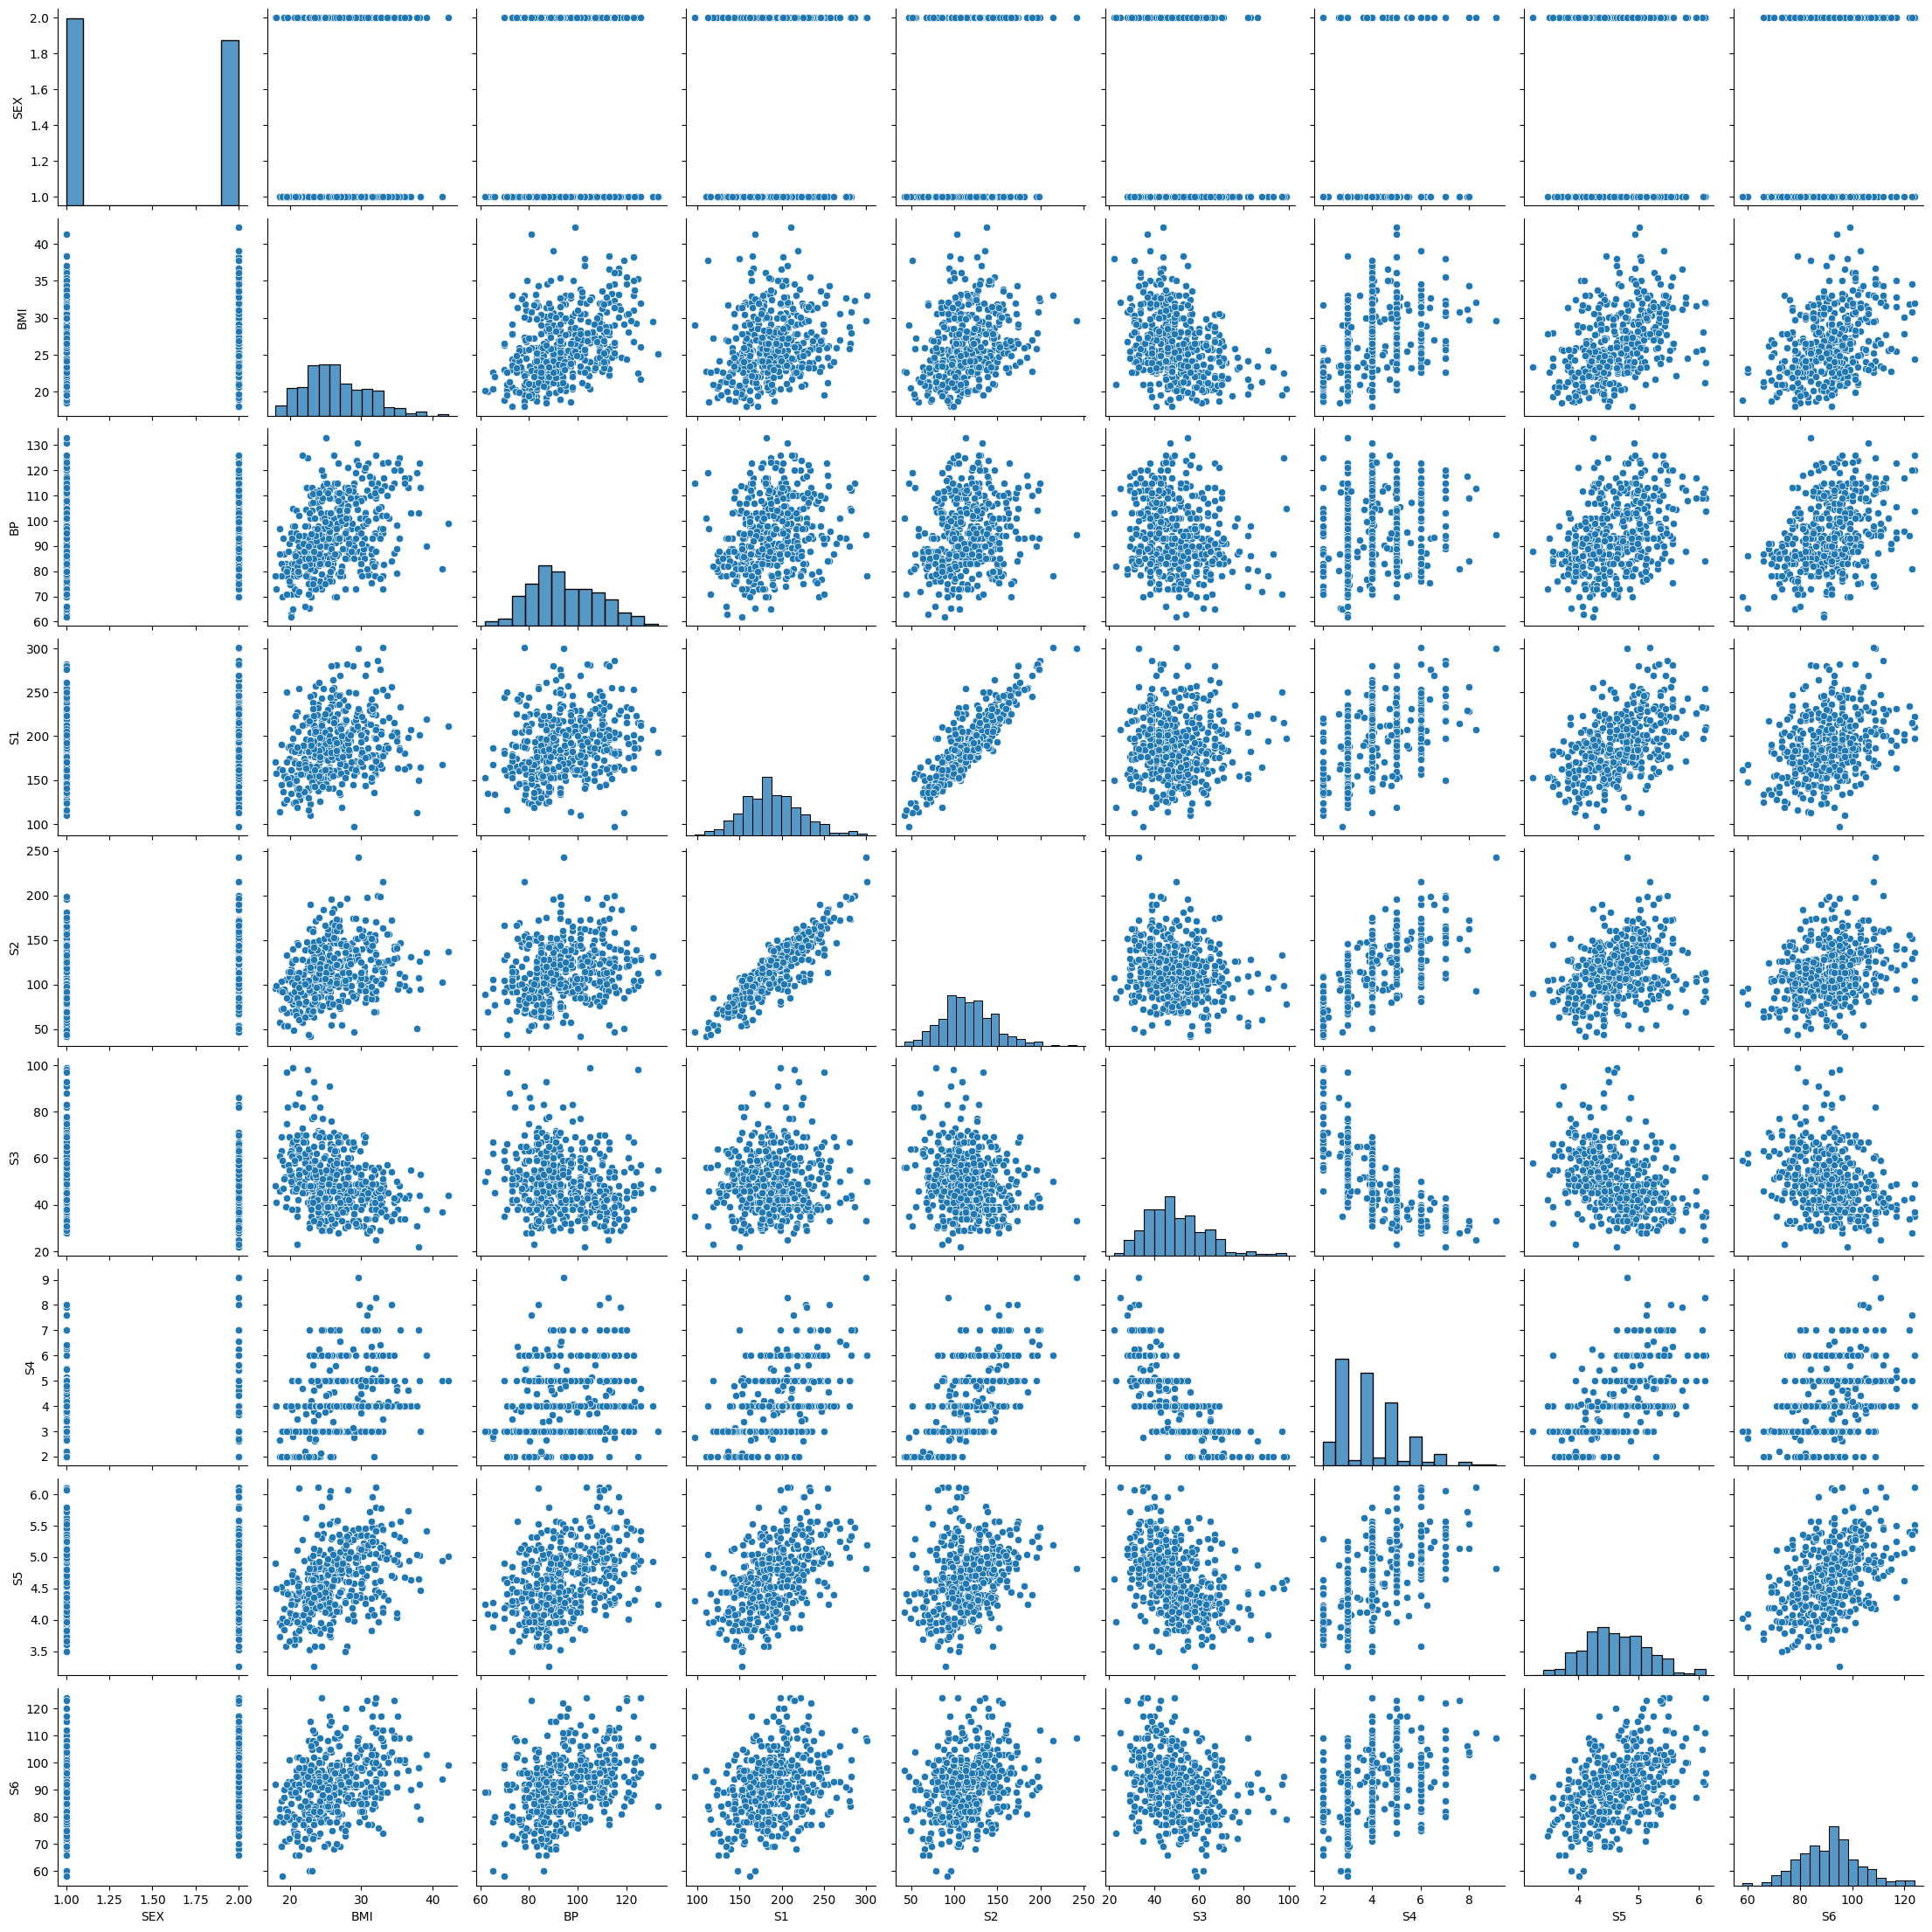

In [7]:
# Plot the distribution of the data
sns.pairplot(data=diabetes_data.drop('PROGRESSION', axis=1))

Let us normalise our data using MinMaxScaler. Please note that we fit it on the training set.

In [8]:
# Fit the scaler on the train data
sc = MinMaxScaler()
sc.fit(X_train)

# Apply the scaler on the train and test data
X_train = sc.transform(X_train)
X_test = sc.transform(X_test)

Fit the model on the training data

In [10]:
# Fit a model
lm = LinearRegression()
model = lm.fit(X_train, y_train)
predictions = lm.predict(X_test)

# Create line coordinates
X_line = np.empty(X_test.shape)
for i in range(X_test.shape[1]):
    X_line[:, i] = np.linspace(np.min(X_test[:,i]), np.max(X_test[:,i]), num=X_test.shape[0])
y_line = lm.predict(X_line)

print('Intercept: \n', lm.intercept_)    
print('Coefficients: \n', lm.coef_)

Intercept: 
 [97.]
Coefficients: 
 [[ 2.03764836e-14 -3.73034936e-14  2.66453526e-14  2.04000000e+02
  -8.92619312e-14 -1.82076576e-14  2.46469511e-14 -4.41868764e-14
  -6.63913369e-14 -3.32650574e-14]]


Predictions for the test set

In [11]:
# Predictions
predictions[0:5]

array([[199.],
       [215.],
       [240.],
       [153.],
       [177.]])

Sklearn's LinearRegression provides the R squared score for its models

In [13]:
# R squared score
print("R2 Score:", round(model.score(X_test, Y_test), 4))

R2 Score: 1.0


In [14]:
from sklearn.metrics import r2_score
r2 = r2_score(Y_test, predictions)

# print the R squared score
print(f"R squared score: {r2}")

R squared score: 1.0


This score is 1, which suggests that our model fits our observation 